# Спортивные фотографии: residual CNN с нуля

Классификация изображений по 30 видам спорта. Собственные Dataset и сеть из четырёх residual-блоков, аугментации, AdamW, CyclicLR и сохранение checkpoint.

4002 train-изображения и 150 отложенных. Отложенная часть названа `test` в коде, но используется для выбора checkpoint и служит validation. Отдельного финального test нет.

Совместная лабораторная работа с Кириллом Слепцовым.

[Результаты и запуск](../docs/computer-vision.md) · [Источники](../PROVENANCE.md)

## 1. Библиотеки и seed

Seed 42 для Python, NumPy и PyTorch.

In [3]:

import PIL
import torchvision
from PIL import Image
from torchvision.transforms import v2

import pandas as pd
import numpy as np
import random
import torch
import os
from tqdm.auto import tqdm

def set_seed(seed: int = 42) -> None:
    
    np.random.seed(seed)
    
    random.seed(seed)
    
    torch.manual_seed(seed)
    
    torch.cuda.manual_seed(seed)
    
    torch.backends.cudnn.deterministic = True
    
    torch.backends.cudnn.benchmark = False
    
    os.environ["PYTHONHASHSEED"] = str(seed)
    print(f"Random seed set as {seed}")

set_seed()

Random seed set as 42


## 2. Данные

Распакуйте `sports.zip` в `data/sports/` либо задайте `SPORTS_DATA_DIR`. Нужны `sports.csv` и фотографии по путям из CSV. Ноутбук переходит в папку данных.

In [4]:
from pathlib import Path
import os

REPO_DIR = Path.cwd()
if REPO_DIR.name == "notebooks":
    REPO_DIR = REPO_DIR.parent
DATA_DIR = Path(os.environ.get("SPORTS_DATA_DIR", str(REPO_DIR / "data" / "sports"))).expanduser().resolve()
if not (DATA_DIR / "sports.csv").is_file():
    raise FileNotFoundError(f"Распакуйте sports.zip: ожидается {DATA_DIR / 'sports.csv'}")
os.chdir(DATA_DIR)


### Описание фотографий

CSV содержит относительный путь, класс и принадлежность к разбиению.

In [5]:

df = pd.read_csv('sports.csv')

df.head(10)

,class id,filepaths,labels,data set
0,0,train/air hockey/001.jpg,air hockey,train
1,0,train/air hockey/002.jpg,air hockey,train
2,0,train/air hockey/003.jpg,air hockey,train
3,0,train/air hockey/004.jpg,air hockey,train
4,0,train/air hockey/005.jpg,air hockey,train
5,0,train/air hockey/006.jpg,air hockey,train
6,0,train/air hockey/007.jpg,air hockey,train
7,0,train/air hockey/008.jpg,air hockey,train
8,0,train/air hockey/009.jpg,air hockey,train
9,0,train/air hockey/010.jpg,air hockey,train


### Пример изображения

In [6]:

img_example = Image.open(df['filepaths'][0])

img_example



### Список классов

In [7]:

sport = pd.unique(df['labels'])

print(len(sport), sport)

100 ['air hockey' 'ampute football' 'archery' 'arm wrestling' 'axe throwing'
 'balance beam' 'barell racing' 'baseball' 'basketball' 'baton twirling'
 'bike polo' 'billiards' 'bmx' 'bobsled' 'bowling' 'boxing' 'bull riding'
 'bungee jumping' 'canoe slamon' 'cheerleading' 'chuckwagon racing'
 'cricket' 'croquet' 'curling' 'disc golf' 'fencing' 'field hockey'
 'figure skating men' 'figure skating pairs' 'figure skating women'
 'fly fishing' 'football' 'formula 1 racing' 'frisbee' 'gaga'
 'giant slalom' 'golf' 'hammer throw' 'hang gliding' 'harness racing'
 'high jump' 'hockey' 'horse jumping' 'horse racing' 'horseshoe pitching'
 'hurdles' 'hydroplane racing' 'ice climbing' 'ice yachting' 'jai alai'
 'javelin' 'jousting' 'judo' 'lacrosse' 'log rolling' 'luge'
 'motorcycle racing' 'mushing' 'nascar racing' 'olympic wrestling'
 'parallel bar' 'pole climbing' 'pole dancing' 'pole vault' 'polo'
 'pommel horse' 'rings' 'rock climbing' 'roller derby'
 'rollerblade racing' 'rowing' 'rugby' 'sail

### Разбиение

Используем готовые части `train` и `test` из CSV.

In [8]:

train_df = df.loc[df['data set'] == 'train']

test_df = df.loc[df['data set'] == 'test']

### Подвыборка

Берём первые 30 классов в порядке CSV и кодируем их целыми числами от 0 до 29. Получаем 4002 train-изображения и 150 отложенных.

In [9]:

selected = sport[:30]

class_to_id = {name: i for i, name in enumerate(selected)}

print(f"Берём только {len(selected)} классов из {len(sport)}:")
print(list(selected))

train_df = train_df[train_df['labels'].isin(selected)]

test_df = test_df[test_df['labels'].isin(selected)]

train_images = []

for path, label in tqdm(zip(train_df['filepaths'], train_df['labels']), total=len(train_df)):
    
    train_images.append((Image.open(path), class_to_id[label]))

test_images = []

for path, label in tqdm(zip(test_df['filepaths'], test_df['labels']), total=len(test_df)):
    
    test_images.append((Image.open(path), class_to_id[label]))

Берём только 30 классов из 100:
['air hockey', 'ampute football', 'archery', 'arm wrestling', 'axe throwing', 'balance beam', 'barell racing', 'baseball', 'basketball', 'baton twirling', 'bike polo', 'billiards', 'bmx', 'bobsled', 'bowling', 'boxing', 'bull riding', 'bungee jumping', 'canoe slamon', 'cheerleading', 'chuckwagon racing', 'cricket', 'croquet', 'curling', 'disc golf', 'fencing', 'field hockey', 'figure skating men', 'figure skating pairs', 'figure skating women']


## 3. Аугментации

Отражения, ElasticTransform и перестановка цветовых каналов. В демонстрации параметры усилены; настройки обучения заданы в Dataset.

In [10]:

import matplotlib.pyplot as plt

img_pil, _ = train_images[0]

img = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])(img_pil)

aug = v2.Compose([
    
    v2.RandomHorizontalFlip(p=0.6),
    
    v2.RandomVerticalFlip(p=0.5),
    
    v2.ElasticTransform(alpha=50.0, sigma=8.0),
    
    v2.RandomChannelPermutation(),
])

fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))

axes[0].imshow(img.permute(1, 2, 0))
axes[0].set_title('оригинал')

for ax in axes[1:]:
    
    ax.imshow(aug(img).permute(1, 2, 0).clamp(0, 1))
    ax.set_title('аугментация')
for ax in axes:
    
    ax.axis('off')
plt.show()



### Dataset

`SportDataset` преобразует изображения в float32 и хранит их в памяти. Аугментации применяются только на train. Нормализация использует mean/std ImageNet; предобученные веса при этом не загружаются.

In [11]:
from torchvision.transforms import v2
import torch
from torch.utils.data import Dataset, DataLoader
import random

class SportDataset(Dataset):
    
    def __init__(self, source, is_train=True):
        
        self.is_train = is_train
        
        self.basic_transform = v2.Compose([
            
            v2.ToImage(),
            
            v2.ToDtype(torch.float32, scale=True),
        ])
        
        self.aug_transform = v2.Compose([

           v2.RandomHorizontalFlip(p=0.5),
           
           v2.RandomVerticalFlip(p=0.2),
           
           v2.ElasticTransform(alpha=30.0, sigma=5.0),
           
           v2.RandomChannelPermutation(),

        ])
        
        self.normalize = v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

        data, target = list(zip(*source))
        
        self.data = list(map(self.basic_transform, data))
        
        self.target = torch.tensor(target)

    def __getitem__(self, index):
        
        image, label = self.data[index], self.target[index]

        if self.is_train:
          
          image = self.aug_transform(image)

        image = self.normalize(image)

        return image, label

    def __len__(self):
        
        return len(self.data)

### DataLoader

Batch size: 64 на train, 512 на отложенной части. За эпоху — 63 обучающих батча и один отложенный из 150 изображений.

In [12]:

dataset_train = SportDataset(train_images, is_train=True)

dataset_test = SportDataset(test_images, is_train=False)

dataloader_train = DataLoader(
    dataset=dataset_train,
    
    batch_size=64,
    
    shuffle=True,
)

dataloader_test = DataLoader(
    dataset=dataset_test,
    
    batch_size=512,
    
    shuffle=True,
)

### Формы тензоров

В сохранённом запуске: изображения `[64, 3, 224, 224]`, метки `[64]`.

In [13]:

X, y = next(iter(dataloader_train))
print(X.shape, y.shape)   
print(y.unique())         

torch.Size([64, 3, 224, 224]) torch.Size([64])
tensor([ 0,  1,  2,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 16, 17, 18, 19,
        20, 21, 23, 24, 25, 26, 27, 28, 29])


## 4. Графики обучения

История loss и accuracy по эпохам.

In [14]:
import matplotlib.pyplot as plt
from IPython.display import clear_output

def show_loss(iter_list, train_loss_list, test_loss_list, test_accuracy_list):
    
    clear_output(wait=True)

    fig, ax = plt.subplots(1, 3, figsize=(16, 5))

    ax[0].plot(iter_list[1:], train_loss_list[1:])
    ax[1].plot(iter_list, test_loss_list)
    ax[2].plot(iter_list, test_accuracy_list)

    ax[0].set_title('Train Loss')
    ax[1].set_title('Test Loss')
    ax[2].set_title('Test Accuracy')
    plt.show()

def get_lr(optimizer):
    
    for param_group in optimizer.param_groups:
        
        return param_group['lr']

## 5. Residual CNN

Блок вычисляет `ReLU(F(x) + shortcut(x))`. Если размер или число каналов меняется, shortcut использует проекцию 1×1 со stride и BatchNorm.

Сеть: входная свёртка и pooling, четыре residual-стадии с 64, 128, 256 и 512 каналами, adaptive average pooling и Linear на 30 классов.

In [15]:
import torch.nn.functional as F
from torch import nn

class ResidualBlock(nn.Module):
    
    def __init__(self, in_channels, out_channels, stride=1, downsample=None):
        
        super(ResidualBlock, self).__init__()
        
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3,
                               stride=stride, padding=1, bias=False)
        
        self.bn1 = nn.BatchNorm2d(out_channels)
        
        self.relu = nn.ReLU(inplace=True)
        
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3,
                               stride=1, padding=1, bias=False)
        
        self.bn2 = nn.BatchNorm2d(out_channels)
        
        self.downsample = downsample

    def forward(self, x):
        
        identity = x

        out = self.conv1(x)
        
        out = self.bn1(out)
        
        out = self.relu(out)
        
        out = self.conv2(out)
        
        out = self.bn2(out)

        if self.downsample is not None:
            
            identity = self.downsample(x)

        out = out + identity
        
        out = self.relu(out)
        return out

class ResidualCNN(nn.Module):
    
    def __init__(self, num_classes=100):
        
        super(ResidualCNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        
        self.bn1 = nn.BatchNorm2d(64)
        
        self.relu = nn.ReLU(inplace=True)
        
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        self.layer1 = self._make_layer(64, 64, stride=1)
        
        self.layer2 = self._make_layer(64, 128, stride=2)
        
        self.layer3 = self._make_layer(128, 256, stride=2)
        
        self.layer4 = self._make_layer(256, 512, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        
        self.flatten = nn.Flatten()
        
        self.fc = nn.Linear(512, num_classes)

    def _make_layer(self, in_channels, out_channels, stride, num_blocks=1):
        
        downsample = None
        
        if stride != 1 or in_channels != out_channels:

            downsample = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1,
                          stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        
        layers = [ResidualBlock(in_channels, out_channels, stride, downsample)]
        
        for _ in range(num_blocks - 1):
            
            layers.append(ResidualBlock(out_channels, out_channels))
        
        return nn.Sequential(*layers)

    def forward(self, x):
        
        out = self.conv1(x)
        
        out = self.bn1(out)
        
        out = self.relu(out)
        
        out = self.maxpool(out)

        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)

        out = self.avgpool(out)
        
        out = self.flatten(out)
        
        out = self.fc(out)
        return out

### Функция оценки

`calc_accuracy` возвращает accuracy, loss, предсказания и метки; `model.eval()` вызывается снаружи. Loss суммируется по батчам. На отложенной части один батч, поэтому loss равен среднему по 150 примерам.

In [16]:

def calc_accuracy(model, dataloader, max_batches=None):
    
    y_pred, y_test = [], []
    
    loss_sum = 0
    
    with torch.no_grad():
        
        for i, (X, target) in enumerate(dataloader):
            
            if max_batches and i >= max_batches:
                break
            
            X, target = X.to(device), target.to(device)
            
            logits = model(X)
            
            loss_sum += loss_fn(logits, target)
            
            y_pred.append(logits.argmax(dim=1))
            
            y_test.append(target)
    
    y_pred = torch.cat(y_pred)
    
    y_test = torch.cat(y_test)
    
    accuracy = torch.sum(y_pred == y_test) / len(y_test)
    
    return accuracy.cpu(), loss_sum.item(), y_pred, y_test

## 6. Параметры обучения

Обучение с нуля на CUDA, 30 эпох, CrossEntropyLoss и AdamW (`lr=1e-3`, `weight_decay=1e-3`). CyclicLR меняет lr от 1e-4 до 1e-2 с подъёмом за 1000 батчей. Scheduler вызывается после каждого шага оптимизатора.

In [17]:

from torch.optim import AdamW
from torch.optim.lr_scheduler import CyclicLR
from torch import nn

device = 'cuda'

n_epoch = 30

model = ResidualCNN(num_classes=30).to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)

scheduler = CyclicLR(optimizer, base_lr=1e-4, max_lr=1e-2, step_size_up=1000, mode='triangular')

### Checkpoint

Сохраняются эпоха, веса модели, состояние оптимизатора и loss. Scheduler и состояния генераторов случайных чисел в checkpoint не входят.

In [18]:

def save_checkpoint(epoch, model, optimizer, loss, path="checkpoint.pth"):
    
    torch.save({
        'epoch': epoch,
        
        'model_state_dict': model.state_dict(),
        
        'optimizer_state_dict': optimizer.state_dict(),
        'loss': loss,
    }, path)

def load_checkpoint(path="checkpoint.pth", model=None, optimizer=None):
    
    checkpoint = torch.load(path,map_location=device)

    if model:
        
        model.load_state_dict(checkpoint['model_state_dict'])
    if optimizer:
        
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

    epoch = checkpoint['epoch']
    loss = checkpoint['loss']

    return model, optimizer, epoch, loss

## 7. Обучение

30 эпох с сохранением checkpoint по лучшей accuracy на отложенной части. После обучения восстанавливаются эти веса.

На последней эпохе: train loss **0,026**, accuracy **0,820** (123/150). Отложенная часть используется для выбора checkpoint и является validation.

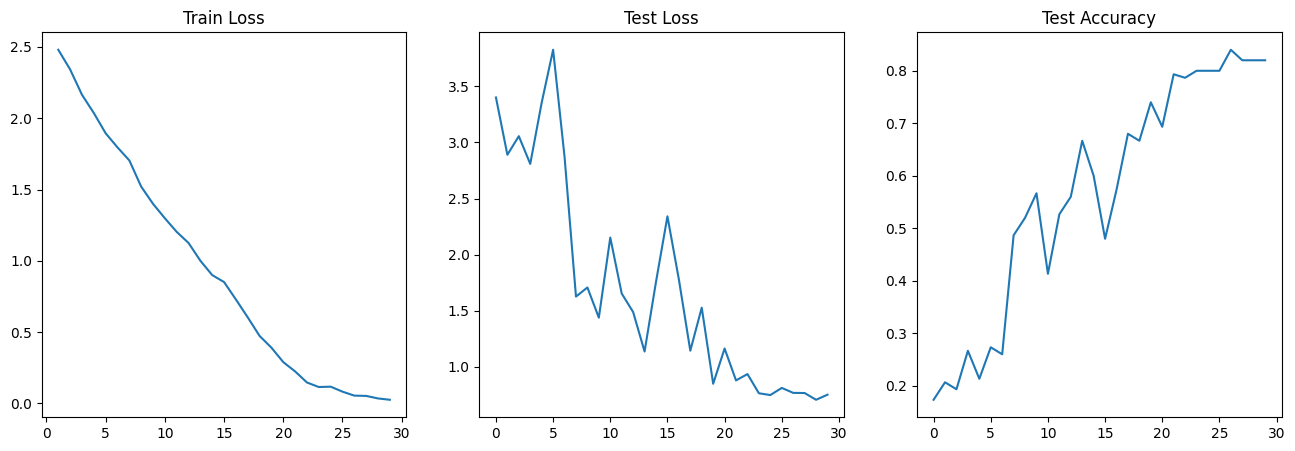

epoch 30: train_loss=0.026, test_acc=0.820, lr=0.00119


In [19]:
from tqdm.auto import tqdm

best_acc = 0.0

iter_list, train_loss_list, test_loss_list, test_acc_list = [], [], [], []

for epoch in range(n_epoch):
    
    model.train()
    
    running_loss = 0.0
    
    for X, target in tqdm(dataloader_train, desc=f'Epoch {epoch+1}/{n_epoch}', leave=False):
        
        X, target = X.to(device), target.to(device)

        logits = model(X)
        
        loss = loss_fn(logits, target)

        optimizer.zero_grad()
        
        loss.backward()
        
        optimizer.step()
        
        scheduler.step()

        running_loss += loss.item() * len(target)

    train_loss = running_loss / len(dataset_train)

    model.eval()
    
    acc, test_loss, _, _ = calc_accuracy(model, dataloader_test)

    iter_list.append(epoch)
    train_loss_list.append(train_loss)
    test_loss_list.append(test_loss)
    
    test_acc_list.append(acc.item())

    if acc.item() > best_acc:
        best_acc = acc.item()
        
        save_checkpoint(epoch, model, optimizer, test_loss, path='best.pth')

    show_loss(iter_list, train_loss_list, test_loss_list, test_acc_list)
    print(f'epoch {epoch+1}: train_loss={train_loss:.3f}, test_acc={acc:.3f}, lr={get_lr(optimizer):.5f}')

model, optimizer, _, _ = load_checkpoint('best.pth', model, optimizer)